# Huynen decomposition

This tutorial applies the Huynen decomposition to the San Francisco ALOS-1 image and saves the result. The function accepts Sinclair (`S`), covariance (`C3`), or coherency (`T3`) datasets and returns a matrix dataset.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from dask.diagnostics import ProgressBar

from polsarpro.decompositions import huynen
from polsarpro.io import open_netcdf_beam, polmat_to_netcdf
from polsarpro.util import S_to_T3, multilook

# Change to your data paths.
input_file = Path("/data/psp/test_files/SAN_FRANCISCO_ALOS1_slc.nc")
output_dir = Path("/data/psp/res")

## Load data

Open the SNAP NetCDF-BEAM scattering matrix. See the Quickstart tutorial for preparing an input dataset.

In [2]:
S = open_netcdf_beam(input_file)
print(S)

<xarray.Dataset> Size: 736MB
Dimensions:  (y: 18432, x: 1248)
Coordinates:
  * y        (y) int64 147kB 0 1 2 3 4 5 ... 18426 18427 18428 18429 18430 18431
  * x        (x) int64 10kB 0 1 2 3 4 5 6 ... 1241 1242 1243 1244 1245 1246 1247
Data variables:
    hh       (y, x) complex64 184MB dask.array<chunksize=(624, 576), meta=np.ndarray>
    hv       (y, x) complex64 184MB dask.array<chunksize=(624, 576), meta=np.ndarray>
    vh       (y, x) complex64 184MB dask.array<chunksize=(624, 576), meta=np.ndarray>
    vv       (y, x) complex64 184MB dask.array<chunksize=(624, 576), meta=np.ndarray>
Attributes:
    poltype:      S
    description:  Scattering matrix


## Prepare the coherency matrix

Convert to T3 and apply four azimuth looks and one range look to reduce the number of image lines.

In [3]:
T3 = S_to_T3(S)
T3 = multilook(T3, dim_az=4, dim_rg=1)
print(T3)

<xarray.Dataset> Size: 207MB
Dimensions:  (y: 4608, x: 1248)
Coordinates:
  * y        (y) float64 37kB 1.5 5.5 9.5 13.5 ... 1.842e+04 1.843e+04 1.843e+04
  * x        (x) float64 10kB 0.0 1.0 2.0 3.0 ... 1.245e+03 1.246e+03 1.247e+03
Data variables:
    m11      (y, x) float32 23MB dask.array<chunksize=(156, 576), meta=np.ndarray>
    m22      (y, x) float32 23MB dask.array<chunksize=(156, 576), meta=np.ndarray>
    m33      (y, x) float32 23MB dask.array<chunksize=(156, 576), meta=np.ndarray>
    m12      (y, x) complex64 46MB dask.array<chunksize=(156, 576), meta=np.ndarray>
    m13      (y, x) complex64 46MB dask.array<chunksize=(156, 576), meta=np.ndarray>
    m23      (y, x) complex64 46MB dask.array<chunksize=(156, 576), meta=np.ndarray>
Attributes:
    poltype:      T3
    description:  Coherency matrix (3x3)


## Apply the decomposition and save the target

Use a 5 × 5 spatial averaging window. `output_basis="pauli"` (the default) returns a T3 dataset; `output_basis="lexicographic"` returns C3. Either output basis is available for every supported input type.

Save the matrix with `polmat_to_netcdf`. An existing output file is overwritten.

In [4]:
target = huynen(T3, boxcar_size=(5, 5), output_basis="pauli")
file_out = output_dir / "psp_huynen.nc"
output_dir.mkdir(parents=True, exist_ok=True)

with ProgressBar():
    polmat_to_netcdf(target, file_out)

[########################################] | 100% Completed | 16.36 s


## Display the target matrix

Reopen the saved dataset with `open_netcdf_beam`.

In [5]:
result = open_netcdf_beam(file_out)
print(result)

<xarray.Dataset> Size: 207MB
Dimensions:  (y: 4608, x: 1248)
Coordinates:
  * y        (y) float64 37kB 1.5 5.5 9.5 13.5 ... 1.842e+04 1.843e+04 1.843e+04
  * x        (x) float64 10kB 0.0 1.0 2.0 3.0 ... 1.245e+03 1.246e+03 1.247e+03
Data variables:
    m11      (y, x) float32 23MB dask.array<chunksize=(156, 576), meta=np.ndarray>
    m22      (y, x) float32 23MB dask.array<chunksize=(156, 576), meta=np.ndarray>
    m33      (y, x) float32 23MB dask.array<chunksize=(156, 576), meta=np.ndarray>
    m12      (y, x) complex64 46MB dask.array<chunksize=(156, 576), meta=np.ndarray>
    m13      (y, x) complex64 46MB dask.array<chunksize=(156, 576), meta=np.ndarray>
    m23      (y, x) complex64 46MB dask.array<chunksize=(156, 576), meta=np.ndarray>
Attributes:
    poltype:      T3
    description:  Coherency matrix (3x3)


Display the diagonal elements. Adjust the color limits for your dataset.

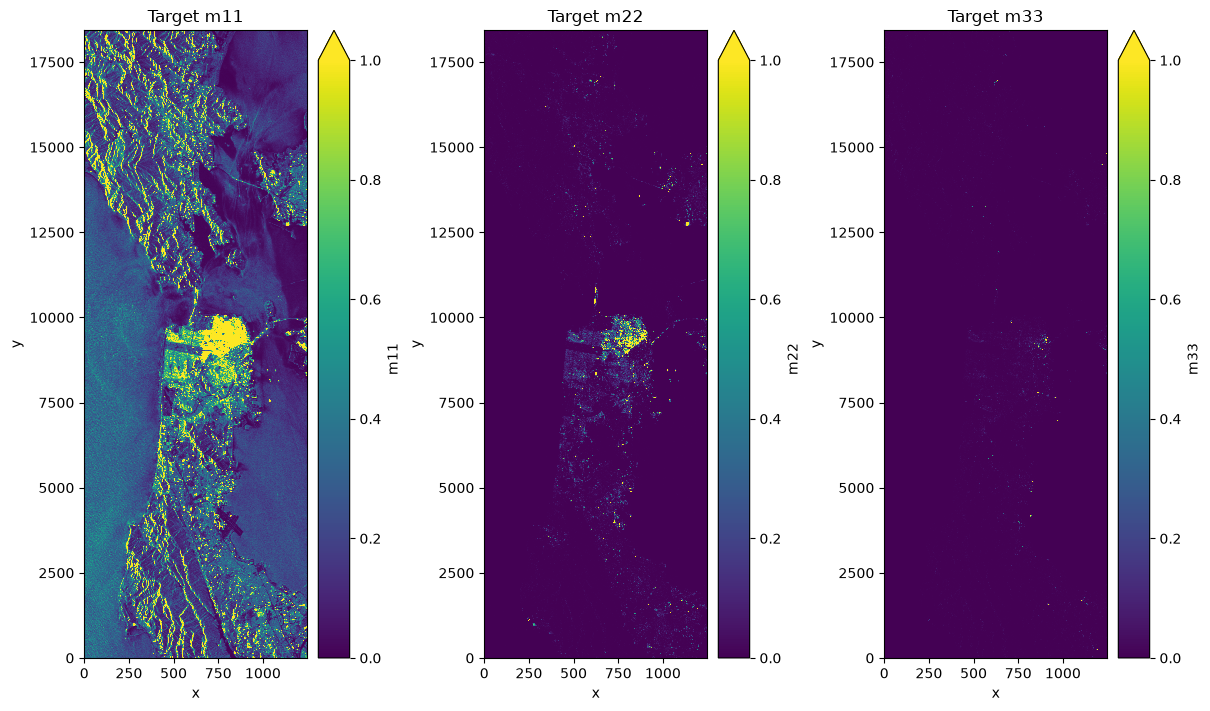

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 7), constrained_layout=True)
for ax, name in zip(axes, ("m11", "m22", "m33")):
    result[name].plot.imshow(ax=ax, vmin=0, vmax=1)
    ax.set_title(f"Target {name}")
plt.show()